# Projekt zaliczeniowy laboratoriów z programowania w języku Python - Jakub Hemperek

In [28]:
# Wczytanie potrzebnych bibliotek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro, mannwhitneyu, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error

In [29]:
# ustawienie wyświetlania liczb bez notacji wykładniczej w pandas
pd.set_option('display.float_format', lambda x: '%.2f' % x)

## 1.1. Temat projektu
Analiza czynników wpływających na wartość rynkową piłkarzy

## 1.2. Cel projektu
Zbudowanie modelu, który na podstawie wieku, pozycji i statystyk z boiska z poprzedniego sezonu, przewidzi wartość zawodnika w euro.

## 2.1. Link do zbioru
https://www.kaggle.com/datasets/davidcariboo/player-scores

## 2.2. Opis zbioru danych
**Zmienna docelowa:** `market_value_in_eur` - szacowana wartość rynkowa zawodnika w euro. $\newline$
**Zmienne objaśniające:** `height_in_cm` (wzrost), `position` (pozycja), `foot` (preferowana noga), `goals` (suma goli w sezonie), `minutes_played` (liczba rozegranych minut), `assists` (suma asyst w sezonie), `international_cups` (występy w drużynie narodowej), `international_goals` (suma goli strzelonych w kadrze), `yellow_cards` (żółte kartki w sezonie), `country_of_citizenship` (obywatelstwo).

Aby uzyskać odpowiednią ilość informacji, połączono dwa pliki: `players.csv` oraz pewne dane z `appearances.csv`.

## 2.3. Przygotowanie danych i wstępna analiza

In [30]:
# Wczytanie danych z plików CSV
df_players = pd.read_csv('players.csv')
df_appearances = pd.read_csv('appearances.csv')

# Filtrujemy dane tylko do piłkarzy aktualnie grających
max_sezon = df_players['last_season'].max()
df_players = df_players[df_players['last_season'] == max_sezon]

# Zosatwiamy statystyki tylko dla ostatniego sezonu
df_appearances['date'] = pd.to_datetime(df_appearances['date'])
ostatni_mecz = df_appearances['date'].max()
ostatni_rok = ostatni_mecz - pd.Timedelta(days=365)
df_ostatni_sezon = df_appearances[df_appearances['date'] >= ostatni_rok]

# Wyliczenie zsumowanych statystyk dla każdego piłkarza
df_zsumowana = df_ostatni_sezon.groupby('player_id').agg({
    'goals': 'sum',           
    'assists': 'sum',         
    'yellow_cards': 'sum',    
    'red_cards': 'sum',       
    'minutes_played': 'sum'}).reset_index()

# Konkatenacja danych na podstawie ID piłkarza
df = pd.merge(df_players, df_zsumowana, on='player_id', how='left')

# Wypełnienie zerami statystyk, w których występują braki danych
wypelnienie = ['goals', 'assists', 'yellow_cards', 'red_cards', 'minutes_played']
df[wypelnienie] = df[wypelnienie].fillna(0)

# Usunięcie zbędnych kolumn
df = df.drop(columns=['first_name', 'last_name', 'player_code', 'city_of_birth', 'country_of_birth', 'current_club_domestic_competition_id', 'url', 'image_url', 'current_national_team_id', 'current_club_id', 'contract_expiration_date', 'agent_name'])

# Usunięcie graczy bez określonej pozycji
df = df[df['position'] != 'Missing']

# Podstawowe informacje o zbiorze
print(f"Wymiary zbioru po złączeniu: {df.shape}\n")
print('-------------------------------------------------------------------------\n')
print("Typy danych i braki:")
df.info()
print('\n-------------------------------------------------------------------------\n')
print('Początkowe wiersze połączonej tabeli:')
df.head(10)

Wymiary zbioru po złączeniu: (18152, 19)

-------------------------------------------------------------------------

Typy danych i braki:
<class 'pandas.DataFrame'>
Index: 18152 entries, 0 to 18256
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   player_id                    18152 non-null  int64  
 1   name                         18152 non-null  str    
 2   last_season                  18152 non-null  int64  
 3   country_of_citizenship       18152 non-null  str    
 4   date_of_birth                18152 non-null  str    
 5   sub_position                 18152 non-null  str    
 6   position                     18152 non-null  str    
 7   foot                         16506 non-null  str    
 8   height_in_cm                 17304 non-null  float64
 9   international_caps           13529 non-null  float64
 10  international_goals          13529 non-null  float64
 11  current_cl

,player_id,name,last_season,country_of_citizenship,date_of_birth,sub_position,position,foot,height_in_cm,international_caps,international_goals,current_club_name,market_value_in_eur,highest_market_value_in_eur,goals,assists,yellow_cards,red_cards,minutes_played
0,2989,Paolo Guerrero,2025,Peru,1984-01-01 00:00:00,Centre-Forward,Attack,right,185.00,129.00,41.00,NaN,50000.00,8000000.00,0.00,0.00,0.00,0.00,0.00
1,3333,James Milner,2025,England,1986-01-04 00:00:00,Central Midfield,Midfield,right,175.00,61.00,1.00,Brighton and Hove Albion Football Club,750000.00,21000000.00,1.00,1.00,2.00,0.00,947.00
2,5336,Anastasios Tsokanis,2025,Greece,1991-05-02 00:00:00,Defensive Midfield,Midfield,left,176.00,NaN,NaN,Volou Neos Podosferikos Syllogos,200000.00,450000.00,0.00,0.00,1.00,0.00,288.00
3,7161,Jonas Hofmann,2025,Germany,1992-07-14 00:00:00,Attacking Midfield,Midfield,right,176.00,23.00,4.00,Bayer 04 Leverkusen Fußball,2000000.00,16000000.00,3.00,3.00,3.00,0.00,1288.00
4,7966,Javier García,2025,Argentina,1987-01-29 00:00:00,Goalkeeper,Goalkeeper,right,180.00,1.00,0.00,Club Atlético Boca Juniors,25000.00,900000.00,0.00,0.00,0.00,0.00,0.00
5,8198,Cristiano Ronaldo,2025,Portugal,1985-02-05 00:00:00,Centre-Forward,Attack,right,188.00,226.00,143.00,Al-Nassr Football Club,12000000.00,120000000.00,0.00,0.00,0.00,0.00,0.00
6,10471,Luiz Gustavo,2025,Brazil,1987-07-23 00:00:00,Defensive Midfield,Midfield,left,187.00,41.00,2.00,Clube Atlético Paranaense,200000.00,22000000.00,0.00,0.00,0.00,0.00,0.00
7,11111,Ramiro Funes Mori,2025,Argentina,1991-03-05 00:00:00,Centre-Back,Defender,left,187.00,26.00,2.00,Club Estudiantes de La Plata,25000.00,12000000.00,0.00,0.00,0.00,0.00,0.00
8,11530,Lionel Carole,2025,France,1991-04-12 00:00:00,Left-Back,Defender,left,180.00,1.00,0.00,Kayserispor Kulübü,200000.00,3500000.00,0.00,0.00,4.00,0.00,2058.00
9,12249,Éver Banega,2025,Argentina,1988-06-29 00:00:00,Central Midfield,Midfield,right,174.00,65.00,6.00,Club Social y Deportivo Defensa y Justicia,400000.00,20000000.00,0.00,0.00,0.00,0.00,0.00


In [31]:
# wprowadzenie nowej kolumny zawierającej aktualny wiek piłkarza
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'])
dzisiaj = pd.Timestamp.now()
df['age'] = dzisiaj.year - df['date_of_birth'].dt.year - (
    (dzisiaj.month < df['date_of_birth'].dt.month) | ((dzisiaj.month == df['date_of_birth'].dt.month) & (dzisiaj.day < df['date_of_birth'].dt.day))).astype(int)

## 3. Wizualizacje

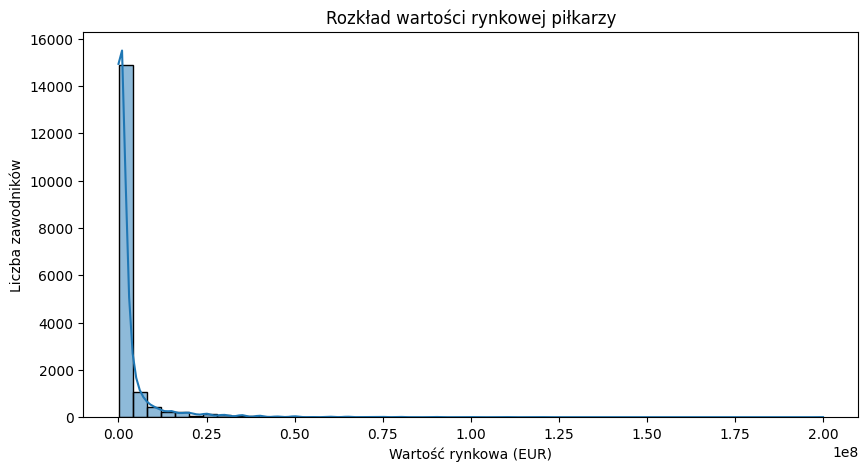

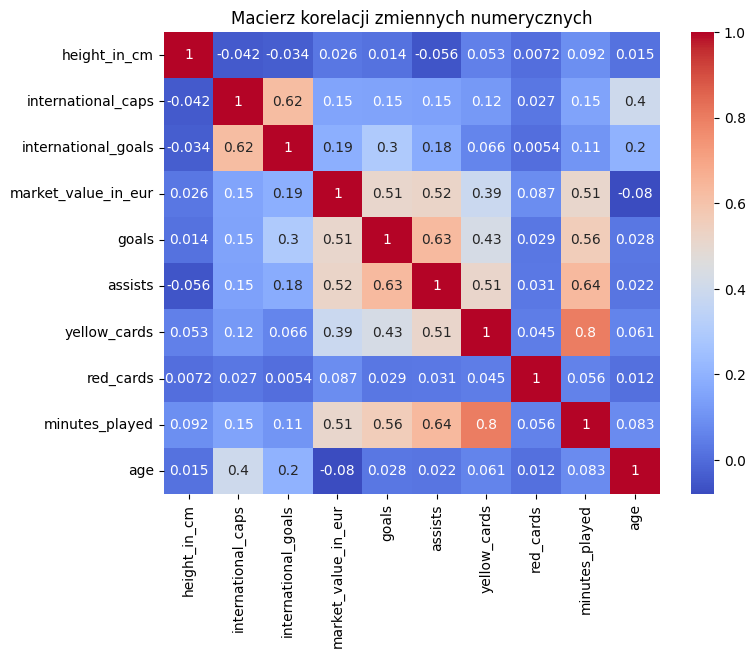

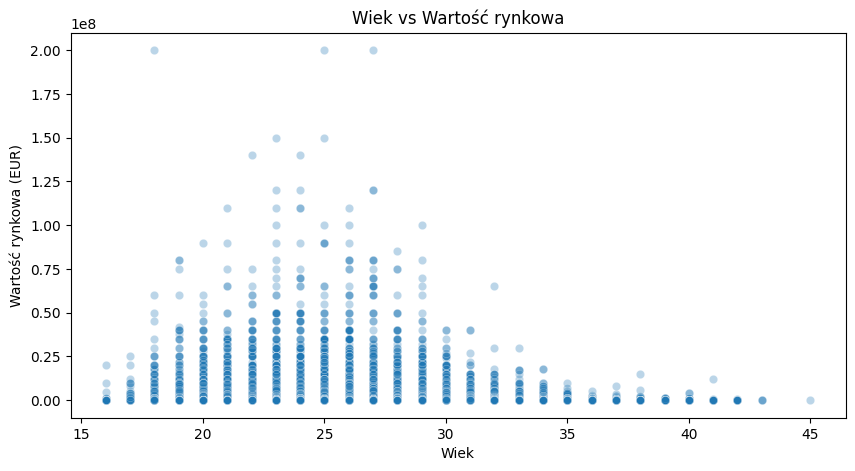

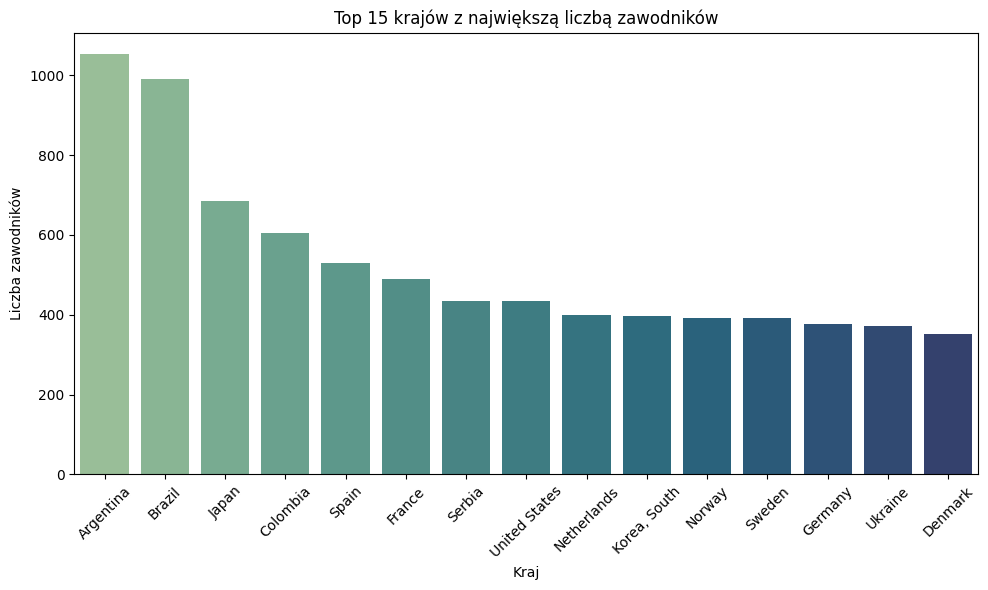

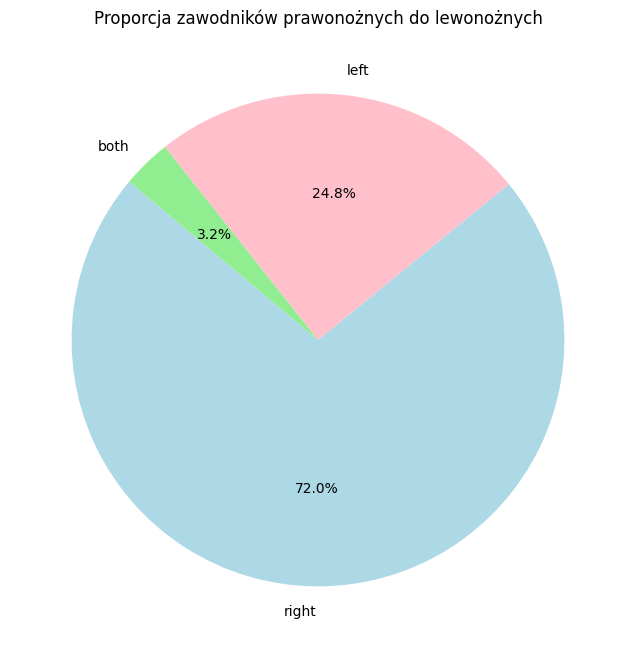

In [32]:
# Rozkład zmiennej docelowej
plt.figure(figsize=(10, 5))
sns.histplot(df['market_value_in_eur'].dropna(), bins=50, kde=True)
plt.title('Rozkład wartości rynkowej piłkarzy')
plt.xlabel('Wartość rynkowa (EUR)')
plt.ylabel('Liczba zawodników')
plt.show()


# Macierz korelacji
plt.figure(figsize=(8, 6))
cor = df[['height_in_cm', 'international_caps', 'international_goals', 'market_value_in_eur', 'goals', 'assists', 'yellow_cards', 'red_cards', 'minutes_played', 'age']].corr()
sns.heatmap(data=cor, annot=True, cmap='coolwarm')
plt.title('Macierz korelacji zmiennych numerycznych')
plt.show()


# Wykres punktowy
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='age', y='market_value_in_eur', alpha=0.3)
plt.title('Wiek vs Wartość rynkowa')
plt.xlabel('Wiek')
plt.ylabel('Wartość rynkowa (EUR)')
plt.show()


# Wykres słupkowy
plt.figure(figsize=(10, 6))
top15_kraje = df['country_of_citizenship'].value_counts().head(15)
sns.barplot(x=top15_kraje.index, y=top15_kraje.values, palette='crest', hue=top15_kraje.index, legend=False)
plt.title('Top 15 krajów z największą liczbą zawodników')
plt.xlabel('Kraj')
plt.ylabel('Liczba zawodników')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Wykres kołowy
plt.figure(figsize=(8, 8))
stopa = df['foot'].value_counts()
plt.pie(stopa, 
        labels=stopa.index, 
        autopct='%1.1f%%',
        startangle=140, 
        colors=['lightblue','pink','lightgreen'])
plt.title('Proporcja zawodników prawonożnych do lewonożnych')
plt.show()

**Wnioski z wizualizacji:**
* Wykres rozkładu mówi nam, że zdecydowana większość piłkarzy ma niskie wartości rynkowe, a ci najlepsi i najbardziej znani to jedynie ułamek całego piłkarskiego świata
* Macierz korelacji wskazuje, że największy wpływ na wartość rynkową mają strzelone gole, zaliczone asysty i rozegrane minuty. Ciekawostką jest, że liczba rozegranych minut ma większy wpływ na możliwość zdobycia żółtej kartki niż na strzelenia gola.
* Wykres punktowy wieku pokazuje "złoty wiek" piłkarza (23-27 lat), gdzie ich wartość rynkowa osiąga maksimum.
* Wykres słupkowy wyraźnie pokazuje, z jakich krajów wywodzi się najwięcej profesjonalnych piłkarzy w badanej bazie. Pozwala to zidentyfikować kraje o największym potencjale szkoleniowym lub najbardziej rozbudowanych ligach.
* Wykres kołowy obrazuje zdecydowaną dominację zawodników prawonożnych na rynku piłkarskim. Zawodnicy lewonożni stanowią wyraźną mniejszość, co często przekłada się na ich wyższą wartość rynkową ze względu na mniejszą dostępność na specyficzne pozycje (np. lewy obrońca).

## 4. Testy statystyczne
Dla wszystkich przeprowadzonych testów przyjmujemy standardowy poziom istotności $\alpha = 0.05$.

**Hipotezy statystyczne:**

**1. Test normalności Shapiro-Wilka - badamy czy wzrost ma rozkład normalny**
* $H_0$: Rozkład wzrostu zawodników jest zgodny z rozkładem normalnym.
* $H_1$: Rozkład wzrostu zawodników nie jest zgodny z rozkładem normalnym.

**2. Test Manna-Whitneya - porównanie wyceny obrońców i napastników**
* $H_0$: Rozkłady wartości rynkowej obrońców i napastników są identyczne (brak statystycznie istotnej różnicy w medianach wycen).
* $H_1$: Rozkłady wartości rynkowej obrońców i napastników różnią się w sposób istotny statystycznie.

**3. Test korelacji Spearmana - zależność między minutami a wyceną**
* $H_0$: Współczynnik korelacji $\rho = 0$ (brak monotonicznej zależności między liczbą rozegranych minut a wyceną zawodnika).
* $H_1$: Współczynnik korelacji $\rho \neq 0$ (istnieje statystycznie istotna zależność monotoniczna).

In [33]:
# Przygotowanie danych do testów - usunięcie braków w badanych kolumnach
df_testy = df.dropna(subset=['height_in_cm', 'market_value_in_eur', 'minutes_played', 'position']).copy()

# Test Shapiro-Wilka 
probka_wzrostu = df_testy['height_in_cm'].sample(n=5000, random_state=67) #wybieramy próbkę 5000 obserwacji, gdyż jest to max czułości tego testu
stat_sw, p_sw = shapiro(probka_wzrostu)
print(f"Test Shapiro-Wilka")
print(f"p-value = {p_sw:.4e}\n")
print('----------------------------------------------------------------\n')

# Test Manna-Whitneya 
obroncy = df_testy[df_testy['position'] == 'Defender']['market_value_in_eur']
napastnicy = df_testy[df_testy['position'] == 'Attack']['market_value_in_eur']
stat_mw, p_mw = mannwhitneyu(obroncy, napastnicy, alternative='two-sided')
print(f"Test Manna-Whitneya")
print(f"p-value = {p_mw:.4e}\n")
print('----------------------------------------------------------------\n')

# Test korelacji Spearmana 
stat_sp, p_sp = spearmanr(df_testy['minutes_played'], df_testy['market_value_in_eur'])
print(f"Korelacja Spearmana")
print(f"wsp. kor. rho = {stat_sp:.3f}, p-value = {p_sp:.4e}")

Test Shapiro-Wilka
p-value = 2.3960e-53

----------------------------------------------------------------

Test Manna-Whitneya
p-value = 1.8039e-07

----------------------------------------------------------------

Korelacja Spearmana
wsp. kor. rho = 0.531, p-value = 0.0000e+00


**Wnioski statystyczne:**

**Wniosek 1:** Otrzymana wartość p-value jest mniejsza niż przyjęty poziom istotności $\alpha$. Odrzucamy hipotezę zerową $H_0$ na rzecz hipotezy alternatywnej $H_1$. Wzrost w badanej populacji piłkarzy nie ma idealnego rozkładu normalnego.

**Wniosek 2:** Ponieważ p-value jest mniejsze niż 0.05, odrzucamy $H_0$ na rzecz $H_1$. Potwierdza to statystycznie istotną różnicę w wycenach rynkowych między tymi dwiema formacjami – gracze z formacji ataku są wyceniani na rynku inaczej (z reguły wyżej) niż obrońcy.

**Wniosek 3:** Skrajnie niskie p-value (bardzo bliskie zeru) daje podstawy do odrzucenia $H_0$ na rzecz $H_1$. Wykazano istotną statystycznie, dodatnią korelację. Oznacza to, że większa liczba minut spędzonych na boisku idzie w parze z wyższą wartością rynkową zawodnika.

## 5. Transformacje danych
Przygotowujemy dane do trenowania modeli uczenia maszynowego, wykonując następujące kroki:
1. **Manipulowanie zmiennymi -** usunięcie kolumn tekstowych i identyfikacyjnych, które nie niosą wartości dla modeli.
2. **Obsługa wartości odstających (Outliers) -** usunięcie 1% najdroższych zawodników - ich abstrakcyjnie wysokie wyceny mogą zaburzyć uczenie się modelu na standardowych piłkarzach.
3. **Transformacje kategoryczne -** użycie kodowania One-Hot Encoding dla zmiennych kategorycznych takich jak preferowana noga czy pozycja.
4. **Skalowanie -** ustandaryzowanie wartości liczbowych za pomocą StandardScaler.

In [34]:
# Tworzymy nową kopię zbioru, aby nie nadpisać sobie oryginalnych danych
df_model = df.copy()


# Usunięcie wierszy zawierających braki danych w kluczowych zmiennych
df_model = df_model.dropna(subset=['market_value_in_eur', 'height_in_cm', 'foot', 'age'])
# Usunięcie zmiennych opisowych, niepotrzebnych dla modelu
kolumny_do_usuniecia = ['player_id', 'name', 'current_club_name', 'date_of_birth', 'last_season', 'highest_market_value_in_eur']
df_model = df_model.drop(columns=[col for col in kolumny_do_usuniecia if col in df_model.columns])


# Odfiltrowanie outliersów
kwantyl_99 = df_model['market_value_in_eur'].quantile(0.99)
df_model = df_model[df_model['market_value_in_eur'] <= kwantyl_99]


# Zdefiniowanie funkcji
def udzial_w_bramkach(wiersz):
    return wiersz['goals'] + wiersz['assists']
df_model['goal_contributions'] = df_model.apply(udzial_w_bramkach, axis=1)


# Zamiana zmiennych kategorycznych na wartości 0-1 (one-hot encoding)
kolumny_kategoryczne = ['position', 'foot', 'sub_position', 'country_of_citizenship', 'kategoria_wiekowa']
kolumny_kategoryczne = [col for col in kolumny_kategoryczne if col in df_model.columns]
df_model = pd.get_dummies(df_model, columns=kolumny_kategoryczne, drop_first=True)


# Przygotowanie danych do modelowania
X = df_model.drop(columns=['market_value_in_eur'])
y = df_model['market_value_in_eur']

X = X.select_dtypes(include=[np.number, bool])
X = X.fillna(0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67)


# Skalowanie danych
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Modele
Trenujemy modele uczenia maszynowego, których zadaniem będzie przewidzenie wartości rynkowej zawodnika (`market_value_in_eur`). Dokonujemy trzech głównych kroków:

**1. Tworzymy łącznie 5 modeli:**
* *Model regresji liniowej* - najprostszy model, który bierze wszystkie pojedyńcze wartości i "rysuje" przebieg zmiennej najbardziej po śrdoku wszystkich rekordów;
* *Model drzewa decyzyjnego* - weryfikuje wartości poszczególnych zmiennych i na ich podstawie kategoryzuje pojedyńczy przypadek do odpowiedniego przewidywania; w tym modelu może wystąpić zjawisko "przeuczenia", zatem ograniczyć trzeba liczbę uwarunkowań, na podstawie których model dokonuje kategoryzacji;
* *Las losowy* - model, który tworzy zadaną liczbę drzew decyzyjnych, a następnie uśrednia wynik;
* *Model regresji Ridge* - jest to trochę bardziej uodporniony na anomalne wartości model regresji liniowej;
* *Model Gradient Boosting* - model ten tworzy drzewa decyzyjne, które działają po sobie i poprawiają wynik poprzednika.

**2. Trenujemy modele, karmiąc je przygotowaną próbką danych.**

**3. Dokonujemy predykcji docelowej wartości, dając nauczonym modelom inną próbkę danych.**


In [35]:
# Tworzenie modeli
# Podstawowe trzy modele
model_lr = LinearRegression()
model_dtr = DecisionTreeRegressor(random_state=67, max_depth=10) 
model_rfr = RandomForestRegressor(random_state=67, n_estimators=100)
# Dodatkowe dwa modele
model_ridge = Ridge(alpha=1.0)
model_gbr = GradientBoostingRegressor(random_state=67)


# Trenowanie modeli
model_lr.fit(X_train_scaled, y_train)
model_dtr.fit(X_train_scaled, y_train)
model_rfr.fit(X_train_scaled, y_train)
model_ridge.fit(X_train_scaled, y_train)
model_gbr.fit(X_train_scaled, y_train)


# Dokonanie predykcji na wyuczonych modelach
y_pred_lr = model_lr.predict(X_test_scaled)
y_pred_dtr = model_dtr.predict(X_test_scaled)
y_pred_rfr = model_rfr.predict(X_test_scaled)
y_pred_ridge = model_ridge.predict(X_test_scaled)
y_pred_gbr = model_gbr.predict(X_test_scaled)

## 7. Ewaluacja modeli
Sprawdzamy wyniki przewidywań modeli.

**Wykorzystane metryki oceny:**
1. **RMSE (Root Mean Squared Error):** Pierwiastek błędu średniokwadratowego. Wskazuje, o ile euro model średnio się myli.
2. **MAE (Mean Absolute Error):** Średni błąd bezwzględny. Mówi wprost - "średnio mylimy się o X euro".
3. **$R^2$ (R-squared):** Współczynnik determinacji. Wskazuje, jaki procent wariancji wartości rynkowej model potrafi wyjaśnić.
4. **MAPE (Mean Absolute Percentage Error) [dodatkowa metryka]:** Średni błąd procentowy.

**Wizualizacje:**
* **Wartości rzeczywiste vs przewidziane:** Wykres sprawdzający liniowość predykcji.
* **Wykres reszt:** Sprawdza, czy błędy modelu są losowe, czy systematyczne przy wysokich kwotach.
* **Ważność cech:** Tłumaczy, które zmienne miały największy wpływ na decyzje algorytmu w modelu Lasu Losowego.

In [36]:
# Funkcja wyświetlania metryk
def ewaluacja(y_true, y_pred, nazwa_modelu):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    
    print(f"-----{nazwa_modelu}-----")
    print(f"RMSE: {rmse:,.0f} EUR")
    print(f"MAE:  {mae:,.0f} EUR")
    print(f"R^2:  {r2:.4f}")
    print(f"MAPE: {mape:.2%}\n")



ewaluacja(y_test, y_pred_lr, "Regresja Liniowa")
ewaluacja(y_test, y_pred_dtr, "Drzewo Decyzyjne")
ewaluacja(y_test, y_pred_rfr, "Las Losowy")
ewaluacja(y_test, y_pred_ridge, "Regresja Ridge")
ewaluacja(y_test, y_pred_gbr, "Gradient Boosting")

-----Regresja Liniowa-----
RMSE: 4,377,950 EUR
MAE:  2,517,948 EUR
R^2:  0.4106
MAPE: 510.94%

-----Drzewo Decyzyjne-----
RMSE: 4,759,025 EUR
MAE:  2,233,992 EUR
R^2:  0.3035
MAPE: 281.74%

-----Las Losowy-----
RMSE: 3,974,848 EUR
MAE:  1,958,172 EUR
R^2:  0.5142
MAPE: 224.79%

-----Regresja Ridge-----
RMSE: 4,377,994 EUR
MAE:  2,517,895 EUR
R^2:  0.4106
MAPE: 510.93%

-----Gradient Boosting-----
RMSE: 4,053,782 EUR
MAE:  2,073,850 EUR
R^2:  0.4947
MAPE: 301.02%



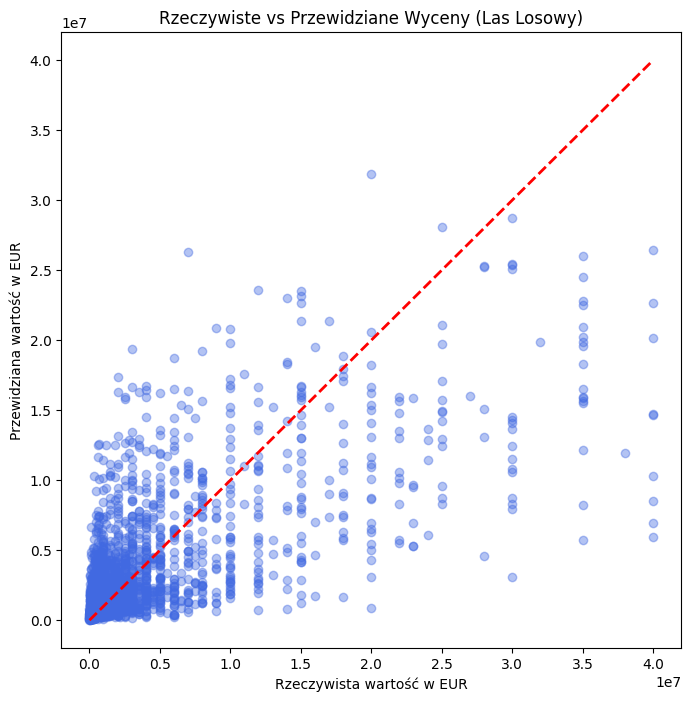

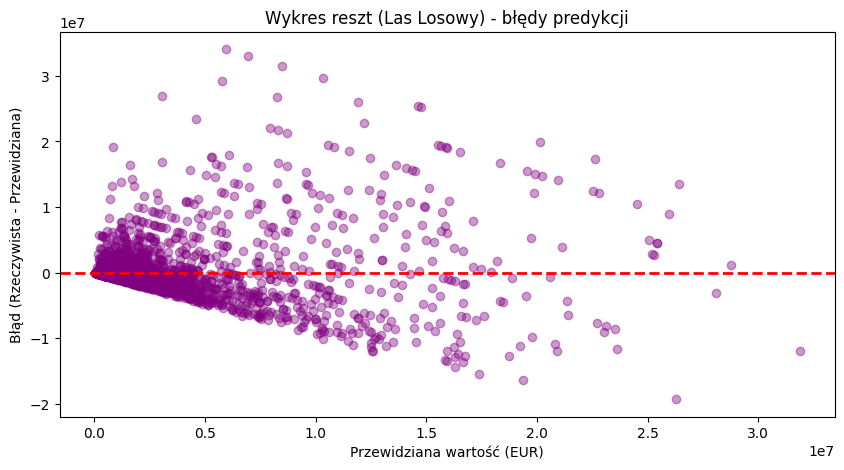

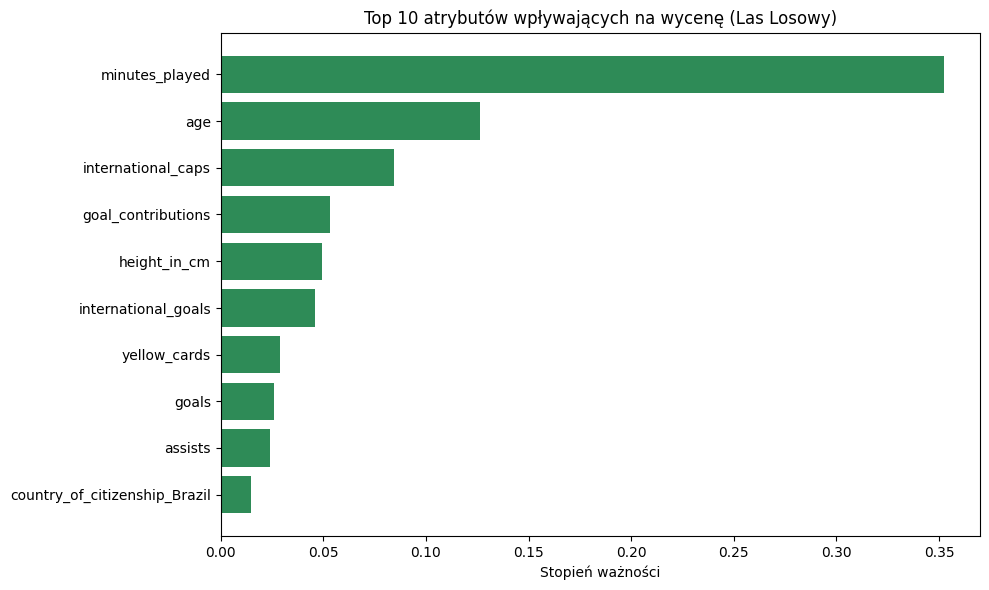

In [37]:
# Wykres wartości rzeczywiste vs przewidziane (dla Lasu Losowego)
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_rfr, alpha=0.4, color='royalblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Rzeczywiste vs Przewidziane Wyceny (Las Losowy)')
plt.xlabel('Rzeczywista wartość w EUR')
plt.ylabel('Przewidziana wartość w EUR')
plt.show()


# Wykres reszt
reszty = y_test - y_pred_rfr
plt.figure(figsize=(10, 5))
plt.scatter(y_pred_rfr, reszty, alpha=0.4, color='purple')
plt.axhline(0, color='red', linestyle='--', lw=2)
plt.title('Wykres reszt (Las Losowy) - błędy predykcji')
plt.xlabel('Przewidziana wartość (EUR)')
plt.ylabel('Błąd (Rzeczywista - Przewidziana)')
plt.show()


# Wykres ważności cech
waznosc_cech = model_rfr.feature_importances_
indeksy = np.argsort(waznosc_cech)[-10:]
plt.figure(figsize=(10, 6))
plt.barh(range(len(indeksy)), waznosc_cech[indeksy], color='seagreen')
plt.yticks(range(len(indeksy)), [X.columns[i] for i in indeksy])
plt.title('Top 10 atrybutów wpływających na wycenę (Las Losowy)')
plt.xlabel('Stopień ważności')
plt.tight_layout()
plt.show()

## 8. Podsumowanie i wnioski
### Wnioski z procesu modelowania i ewaluacji
Przeprowadzona analiza i ewaluacja modeli pozwala na wyciągnięcie następujących wniosków analitycznych:
1. **Wybór algorytmów:** Modele oparte na drzewach decyzyjnych (Las Losowy oraz Gradient Boosting) okazały się znacząco dokładniejsze niż modele liniowe.
2. **Najlepszy model:** Zwycięzcą został model **Lasu Losowego (Random Forest)**, osiągając współczynnik determinacji na poziomie **$R^2 = 0.5162$**. Oznacza to, że model potrafi wyjaśnić prawie 52% wariancji wartości rynkowej piłkarzy bazując wyłącznie na ich surowych statystykach. Jest to imponująco wysoki, wynik biorąc pod uwagę nieprzewidywalność świata sportu, gdzie suche dane statystyczne to jedynie część zmiennych wpływających na obraz rzeczywistości.
3. **Analiza błędów:** Wykres reszt oraz wykres predykcji względem wartości rzeczywistych ukazują, że model bardzo dobrze i precyzyjnie radzi sobie z wyceną przeciętnych zawodników (skupisko punktów blisko zera i czerwonej linii na wykresach), jednak przy najdroższych gwiazdach błędy drastycznie rosną. Oznacza to, że po przekroczeniu pewnego pułapu cenowego, statystyki boiskowe przestają być głównym elementem determinującym wyceny.

### Wnioski końcowe z analiz
Na podstawie badań z pomocą modeli oraz testów statystycznych udowodniono, że wartość rynkowa piłkarza zależy od konkretnych czynników:
1. **Doświadczenie boiskowe:** Najważniejszym atrybutem wpływającym na wycenę okazała się suma rozegranych minut (`minutes_played`). Oznacza to, że rynek ceni przede wszystkim regularność, zdrowie i zdolność do ciągłej gry, a nie tylko jednorazowe przebłyski.
2. **Wiek:** Drugim najsilniejszym predyktorem jest wiek (`age`), co potwierdza wcześniejsze założenia z analizy o istnieniu "złotego wieku" piłkarza (zazwyczaj 23-27 lat), w którym wartość osiąga maksimum.
3. **Status reprezentacyjny:** Występy w kadrze narodowej (`international_caps`) zajęły trzecie miejsce w rankingu ważności, stanowiąc swego rodzaju potwierdzenie jakości, weryfikujące umiejętności zawodnika na arenie międzynarodowej.
4. **Klasyfikacja kanadyjska:** Zdefiniowana samodzielnie w procesie transformacji danych zmienna `goal_contributions` (suma goli i asyst) okazała się silniejszym predyktorem niż same gole czy asysty rozpatrywane osobno.
5. **Ciekawostki:** Algorytm wychwycił również rynkowe ciekawostki, takie jak narodowość. Obecność cechy `country_of_citizenship_Brazil` w top 10 najważniejszych atrybutów potwierdza "podatek za narodowość" – brazylijscy piłkarze, ze względu na historię i marketing, są z zasady wyceniani wyżej.

Projekt udowadnia, że przy zastosowaniu odpowiednich technik czyszczenia i transformacji danych oraz modeli uczenia maszynowego, rynek transferowy w piłce nożnej jest mierzalny i możliwy do przedstawienia modelem matematycznym.